# 03 · Análise exploratória (EDA)

**Objetivo:** descobrir quais sinais separam fraude de transação legítima e transformar isso em
**hipóteses de features** para feature engineering.

> Toda análise que usa o alvo é feita **somente na partição de
> treino** (08/03–31/03). Validação e teste não influenciam nenhuma decisão de modelagem. A única
> exceção é a checagem de estabilidade das distribuições (seção 8), que não usa o alvo.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

from sklearn.metrics import roc_auc_score

In [2]:
base = dados.carregar_base()
tr = base[base["particao"] == "treino"].copy()
y = tr["fraude"]
print(f"Treino: {len(tr):,} transações | taxa de fraude {y.mean():.2%}")

Treino: 76,961 transações | taxa de fraude 5.04%


## 1. Poder discriminante das variáveis numéricas

Para cada variável, calculamos o **ROC AUC univariado**: quão bem ela, sozinha, ordena o risco.
Nulos recebem um valor sentinela, para que a ausência também conte como informação. A coluna `direcao`
indica se valores **maiores** (+) ou **menores** (−) estão associados a mais fraude.

variavel,f,l,m,n,d,h,monto,a,b,e,c,k
auc_univariado,0.6926,0.6752,0.6592,0.6181,0.6133,0.5640,0.5533,0.5413,0.5353,0.5186,0.5057,0.5030
direcao,−,−,−,−,−,−,+,−,+,−,−,+
nulos_%,0.0104,0.0104,0.3261,0.0000,0.3261,0.0000,0.0000,0.0000,16.0094,0.0000,16.0094,0.0000


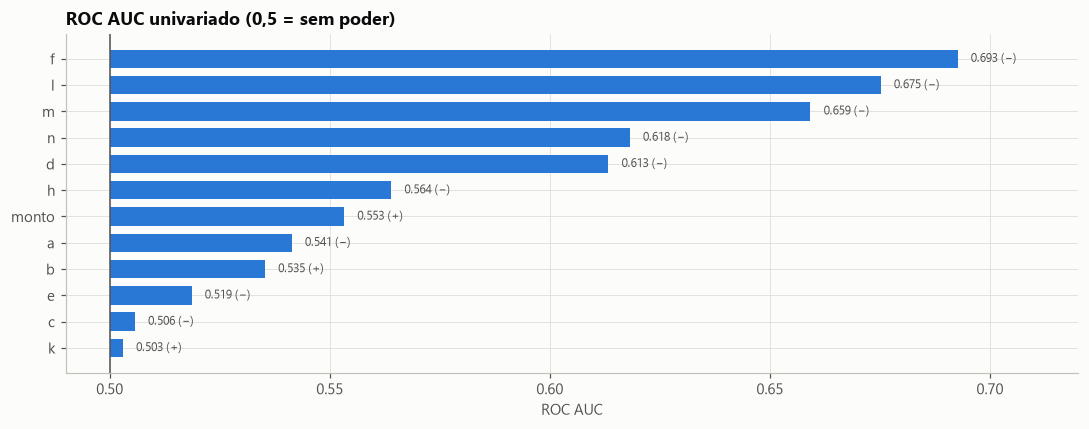

In [3]:
numericas = ["a", "b", "c", "d", "e", "f", "h", "k", "l", "m", "n", "monto"]
linhas = []
for col in numericas:
    auc = roc_auc_score(y, tr[col].fillna(-999))
    linhas.append({"variavel": col, "auc_univariado": max(auc, 1 - auc),
                   "direcao": "+" if auc >= 0.5 else "−", "nulos_%": tr[col].isna().mean() * 100})
poder = pd.DataFrame(linhas).sort_values("auc_univariado", ascending=False).set_index("variavel")

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(poder.index[::-1], poder["auc_univariado"][::-1] - 0.5, left=0.5, color=gr.AZUL, height=0.7)
ax.axvline(0.5, color=gr.TINTA_2, lw=1)
ax.set(title="ROC AUC univariado (0,5 = sem poder)", xlabel="ROC AUC", xlim=(0.49, 0.72))
for i, (v, d) in enumerate(zip(poder["auc_univariado"][::-1], poder["direcao"][::-1])):
    ax.text(v + 0.003, i, f"{v:.3f} ({d})", va="center", fontsize=8, color=gr.TINTA_2)
plt.tight_layout()
poder.T

- **Fortes:** `f`, `l`, `m`, `d`, `n`. Em todas, **valores menores = mais fraude**. Esse padrão é
  compatível com variáveis de *histórico/relacionamento* (ex.: idade da conta, nº de compras
  anteriores, reputação). Fraudadores costumam usar contas novas ou com pouco histórico.
- **Moderadas:** `monto` (valores maiores = mais fraude), `h`, `a`, `b`, `e`.
- **Sem poder individual:** `c` e **`k` (AUC ≈ 0,50)**. `c` pode ainda ajudar em interações; `k`
  investigamos na seção 7.

## 2. Variáveis contínuas ou com muitos valores distintos

- `f`, `l`, `m`, `d`, `b`, `monto`, `h`, `e` e `c`
- Analisamos aqui todas essas 9 por **decis**

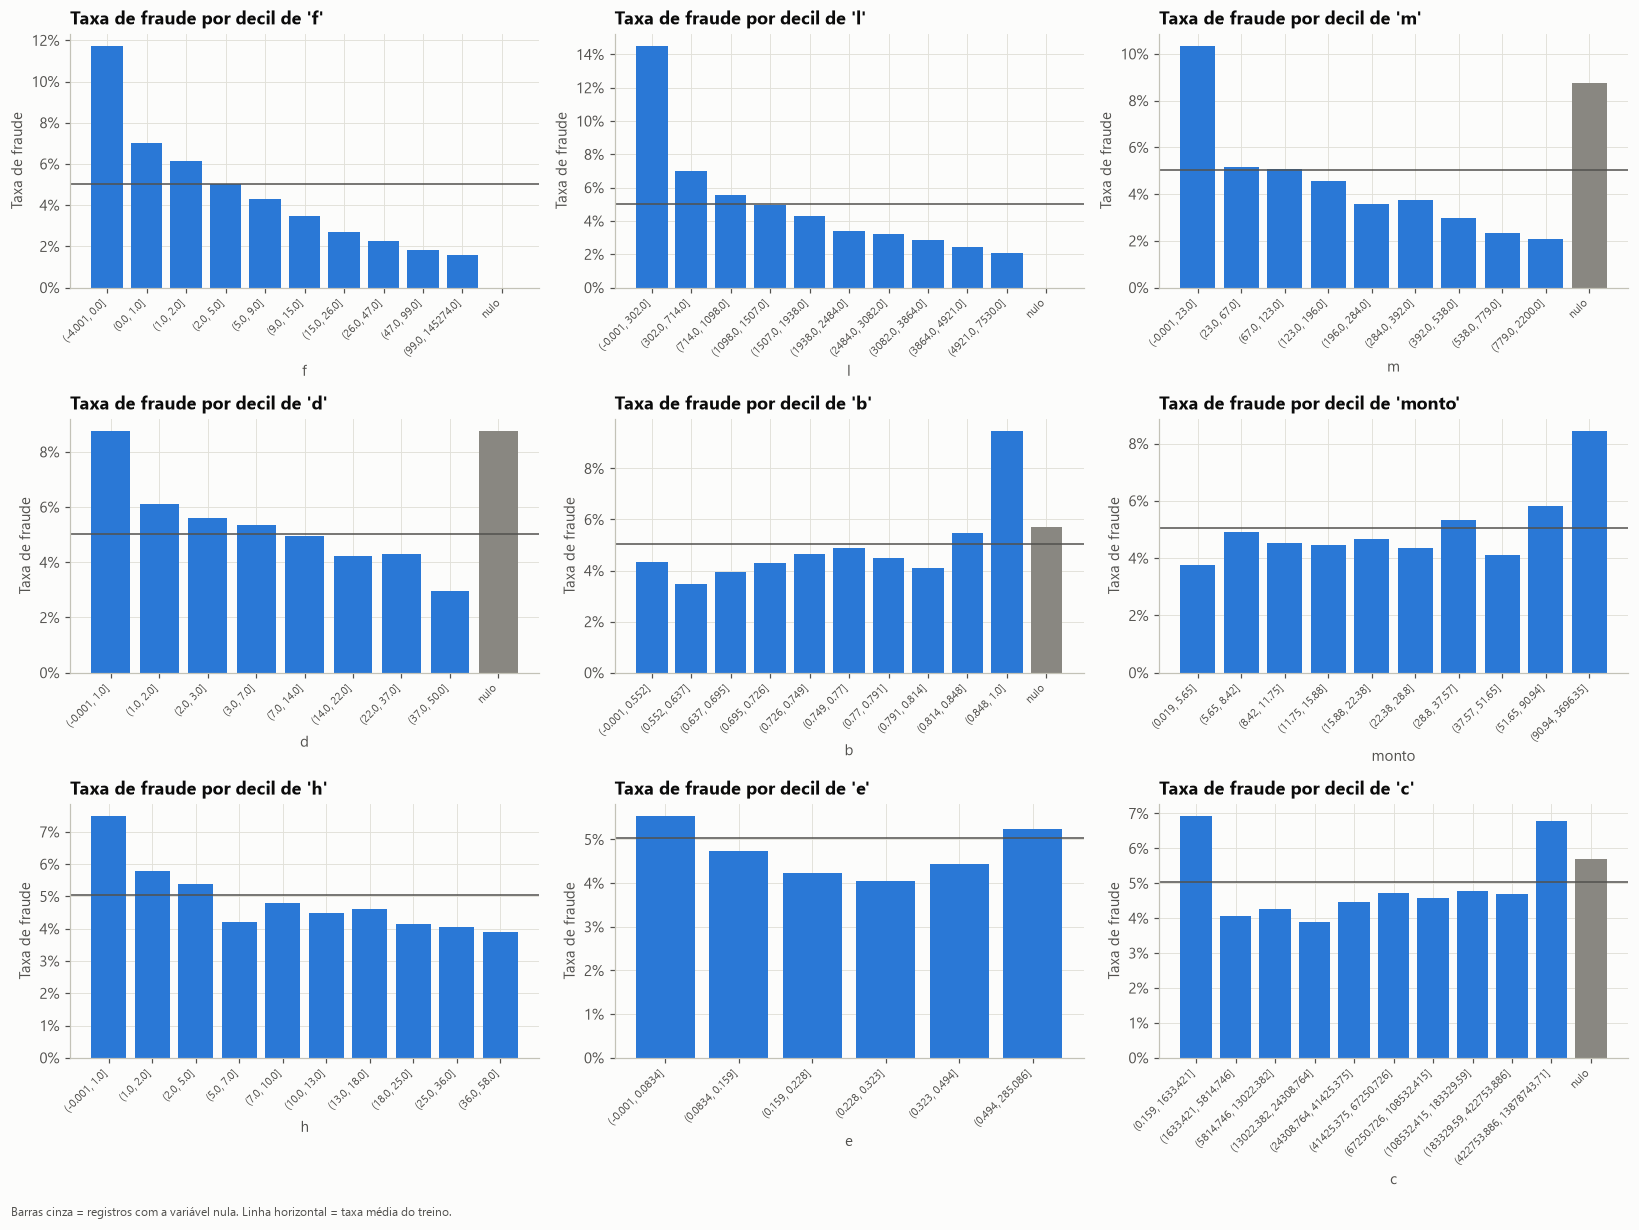

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, ["f", "l", "m", "d", "b", "monto", "h", "e", "c"]):
    gr.taxa_fraude_por_faixa(tr, col, bins=10, ax=ax, titulo=f"Taxa de fraude por decil de '{col}'")
fig.text(0.01, -0.01, "Barras cinza = registros com a variável nula. Linha horizontal = taxa média do treino.",
         fontsize=8, color=gr.TINTA_2)
plt.tight_layout()

As variáveis de histórico (`f`, `l`, `m`, `d` e, mais levemente, `h`) seguem o mesmo padrão, em que o risco se concentra nos **valores mais baixos**, com o 1º decil chegando a 2–3x a taxa média, e cai rapidamente depois. Isso é compatível com contas novas ou com pouco histórico, e os nulos de `d/m` também são arriscados. Já `monto` e `b` mostram o efeito oposto, em que o risco sobe só no topo, nas compras de maior valor e com `b > 0,85`.

`c` e `e` têm risco quase plano, maior apenas nos extremos (bimodal). Por isso o AUC univariado delas fica perto de 0,5, embora carreguem sinal. 

Em geral, os gráficos mostram relações fortemente não lineares e com limiares, que um modelo linear não capturaria sem transformações manuais. Isso sugere uso de modelos de árvore e explica por que nenhuma variável foi descartada só pelo AUC.

## 3. Variáveis categóricas ou com poucos valores distintos

- `o`, `p` (categóricas / nulas), `n` (binária) e `a` (ordinal com 4 níveis).

Analisamos o risco é por **classe**, onde as tabelas mostram as **transações** e **% do volume** da base, **taxa de fraude** e o **risco relativo** (taxa do nível dividida pela taxa média do treino).

O nulo é tratado como um nível próprio ("nulo") para não perdermos informação.

Ao final da seção, a mesma análise é aplicada ao país (`g`).

In [5]:
def perfil_categorica(col, top=8):
    t = (tr.assign(_c=tr[col].astype("string").fillna("nulo"))
           .groupby("_c")["fraude"].agg(transacoes="size", taxa_fraude="mean")
           .sort_values("transacoes", ascending=False).head(top))
    t["%_volume"] = t["transacoes"] / len(tr)
    t["risco_relativo"] = t["taxa_fraude"] / y.mean()
    return t

for col in ["o", "n", "p", "a"]:
    display(perfil_categorica(col).style.format({"taxa_fraude": "{:.2%}", "%_volume": "{:.1%}",
                                                 "risco_relativo": "{:.2f}x"}).set_caption(f"Variável {col}"))

,transacoes,taxa_fraude,%_volume,risco_relativo
_c,,,,
nulo,55797,2.06%,72.5%,0.41x
Y,12582,6.49%,16.3%,1.29x
N,8582,22.24%,11.2%,4.42x


,transacoes,taxa_fraude,%_volume,risco_relativo
_c,,,,
1,69675,3.79%,90.5%,0.75x
0,7286,16.98%,9.5%,3.37x


,transacoes,taxa_fraude,%_volume,risco_relativo
_c,,,,
Y,43196,2.92%,56.1%,0.58x
N,33765,7.74%,43.9%,1.54x


,transacoes,taxa_fraude,%_volume,risco_relativo
_c,,,,
4,64915,4.57%,84.3%,0.91x
2,8409,6.83%,10.9%,1.36x
1,2058,9.09%,2.7%,1.80x
3,1579,9.50%,2.1%,1.89x


- **`o` é a variável mais forte da base:** `N` tem **~4,5x** o risco médio, `Y` fica perto da média e
  o **nulo** (72% do volume) tem menos da metade do risco. Os três estados precisam ser preservados.
- **`n = 0`** (10% do volume) tem **~3,4x** o risco médio.
- **`p = N`** tem ~2,6x o risco de `p = Y`.
- **`a`:** os níveis 1–3 (16% do volume) são 1,5x a 2x mais arriscados que o nível 4.

In [6]:
pais = perfil_categorica("g", top=10)
pais.style.format({"taxa_fraude": "{:.2%}", "%_volume": "{:.1%}", "risco_relativo": "{:.2f}x"})

,transacoes,taxa_fraude,%_volume,risco_relativo
_c,,,,
BR,57371,5.56%,74.5%,1.10x
AR,16629,3.74%,21.6%,0.74x
UY,1369,0.80%,1.8%,0.16x
US,1063,2.63%,1.4%,0.52x
SE,168,2.38%,0.2%,0.47x
MX,124,1.61%,0.2%,0.32x
CO,48,0.00%,0.1%,0.00x
RU,45,2.22%,0.1%,0.44x
nulo,42,9.52%,0.1%,1.89x


**País (`g`):** BR (74% do volume) concentra o maior risco entre os grandes. AR e US ficam abaixo da
média e UY tem risco muito baixo. Os demais países têm volume pequeno demais para estimar uma taxa
própria. 

>**Decisão para próximos passos:** manter só os países com volume relevante e agrupar o resto.

## 4. Variável "fecha"

- Em que dia e hora a fraude "acontece"?

Madrugada (0h-5h): 3.6% do volume, taxa de fraude 11.1% vs 4.8% no resto do dia


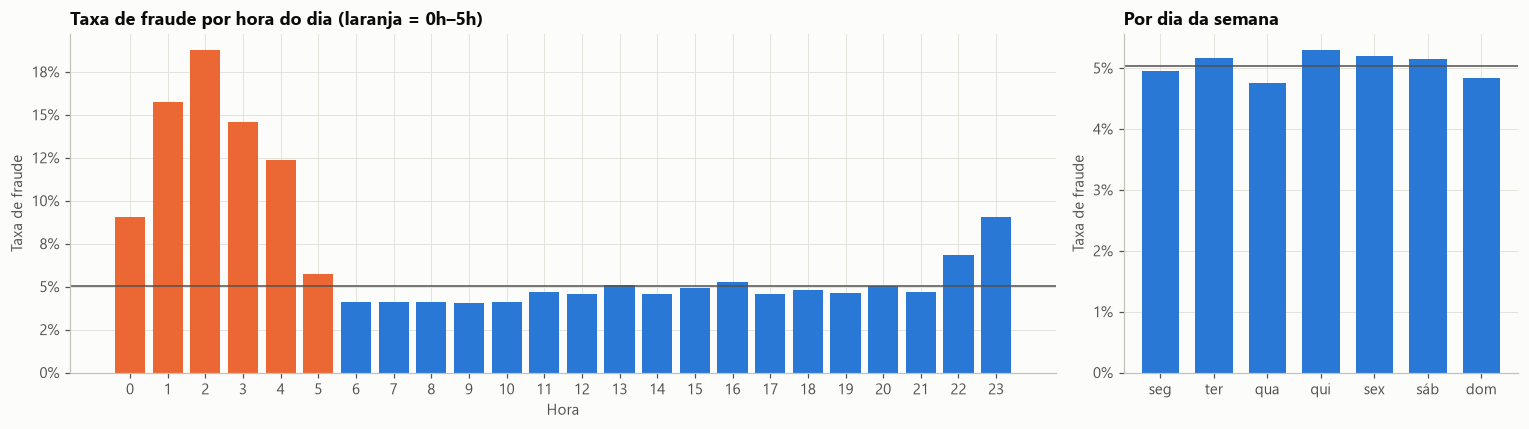

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1.2]})
hora = tr.groupby(tr["fecha"].dt.hour)["fraude"].mean()
axes[0].bar(hora.index, hora.values, color=np.where(hora.index <= 5, gr.LARANJA, gr.AZUL), width=0.8)
axes[0].axhline(y.mean(), color=gr.TINTA_2, lw=1)
axes[0].set(title="Taxa de fraude por hora do dia (laranja = 0h–5h)", xlabel="Hora", ylabel="Taxa de fraude",
            xticks=range(0, 24))
gr.formatar_pct(axes[0])

dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
dsem = tr.groupby(tr["fecha"].dt.day_of_week)["fraude"].mean()
axes[1].bar([dias[i] for i in dsem.index], dsem.values, color=gr.AZUL, width=0.7)
axes[1].axhline(y.mean(), color=gr.TINTA_2, lw=1)
axes[1].set(title="Por dia da semana", ylabel="Taxa de fraude")
gr.formatar_pct(axes[1])
plt.tight_layout()

madrugada = tr["fecha"].dt.hour <= 5
print(f"Madrugada (0h-5h): {madrugada.mean():.1%} do volume, taxa de fraude {y[madrugada].mean():.1%} "
      f"vs {y[~madrugada].mean():.1%} no resto do dia")

Na madrugada, entre **0h e 5h**, a taxa de fraude é **~2,2x** a média (11% contra 5,0%), com pico de ~19% às 2h. Já o dia da semana não mostra efeito relevante.

## 5. Variáveis `j` e `i`

### 5.1 Categoria do produto (`j`)

Analisamos as categorias dividindo por
- Categorias com **< 30** transações;
- Categorias com **> 200** transações.

In [8]:
cat = tr.groupby("j")["fraude"].agg(transacoes="size", taxa_fraude="mean")
print(f"Categorias distintas no treino: {len(cat):,}")
print(f"\nCategorias com < 30 transações: {(cat['transacoes'] < 30).mean():.0%} das categorias, "
      f"{cat.loc[cat['transacoes'] < 30, 'transacoes'].sum() / len(tr):.0%} do volume")

grandes = cat[cat["transacoes"] >= 200].sort_values("taxa_fraude", ascending=False)
print(f"\nEntre as {len(grandes)} categorias com +200 transações, a taxa de fraude vai de "
      f"{grandes['taxa_fraude'].min():.1%} a {grandes['taxa_fraude'].max():.1%}")
grandes.head(40).style.format({"taxa_fraude": "{:.2%}"})

Categorias distintas no treino: 6,974

Categorias com < 30 transações: 93% das categorias, 41% do volume

Entre as 40 categorias com +200 transações, a taxa de fraude vai de 1.2% a 27.1%


,transacoes,taxa_fraude
j,,
cat_d9753d4,291,27.15%
cat_43b9c10,1191,15.45%
cat_bdcf37d,316,11.39%
cat_228843f,358,10.34%
cat_ec06c68,368,10.33%
cat_a349b79,304,9.21%
cat_9ff11b9,298,8.72%
cat_8ef7164,481,8.32%
cat_d5975ae,421,8.31%


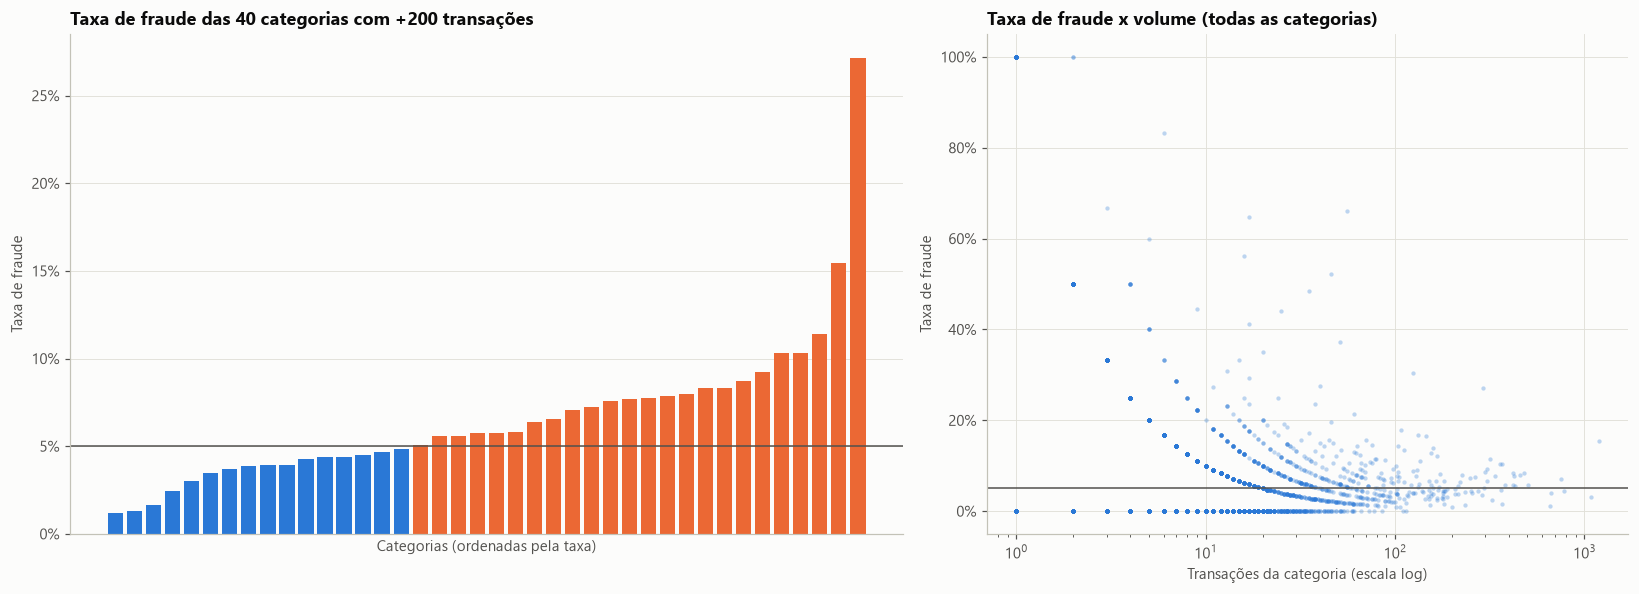

In [9]:
# Esquerda: taxa de fraude das 40 categorias com +200 transações (sinal real entre categorias)
# Direita: taxa x volume de todas as categorias (ruído das categorias pequenas)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

g = grandes.sort_values("taxa_fraude")
axes[0].bar(range(len(g)), g["taxa_fraude"], color=np.where(g["taxa_fraude"] > y.mean(), gr.LARANJA, gr.AZUL), width=0.8)
axes[0].axhline(y.mean(), color=gr.TINTA_2, lw=1)
axes[0].set_xticks([])
axes[0].set(title="Taxa de fraude das 40 categorias com +200 transações", xlabel="Categorias (ordenadas pela taxa)",
            ylabel="Taxa de fraude")
gr.formatar_pct(axes[0])

axes[1].scatter(cat["transacoes"], cat["taxa_fraude"], s=8, alpha=0.3, color=gr.AZUL)
axes[1].axhline(y.mean(), color=gr.TINTA_2, lw=1)
axes[1].set_xscale("log")
axes[1].set(title="Taxa de fraude x volume (todas as categorias)", xlabel="Transações da categoria (escala log)",
            ylabel="Taxa de fraude")
gr.formatar_pct(axes[1])
plt.tight_layout()

- **Esquerda:** entre as categorias com volume suficiente para uma taxa confiável, o risco varia de
  ~1% a ~27%. Laranja = acima da média, azul = abaixo.
- **Direita:** o "funil" mostra o problema da cauda longa. Categorias pequenas (à esquerda) têm taxas
  extremas, 0% ou 100%, por puro acaso amostral. Conforme o volume cresce, as taxas convergem para
  valores estáveis.

A categoria carrega **muito sinal**, visto que entre categorias grandes (200+ transações), a taxa de fraude
vai de ~1% a ~27%. Porém, existe uma **cauda longa** de categorias pequenas, cuja taxa observada é **ruído**.

>**Decisão para próximos passos:** usar uma **codificação pelo alvo com suavização** (*target encoding* com *shrinkage*). Categorias pequenas são puxadas para a média global e categorias grandes mantêm a própria taxa. A codificação será gerada *out-of-fold* para evitar vazamento.

### 5.2 Título do produto (`i`)

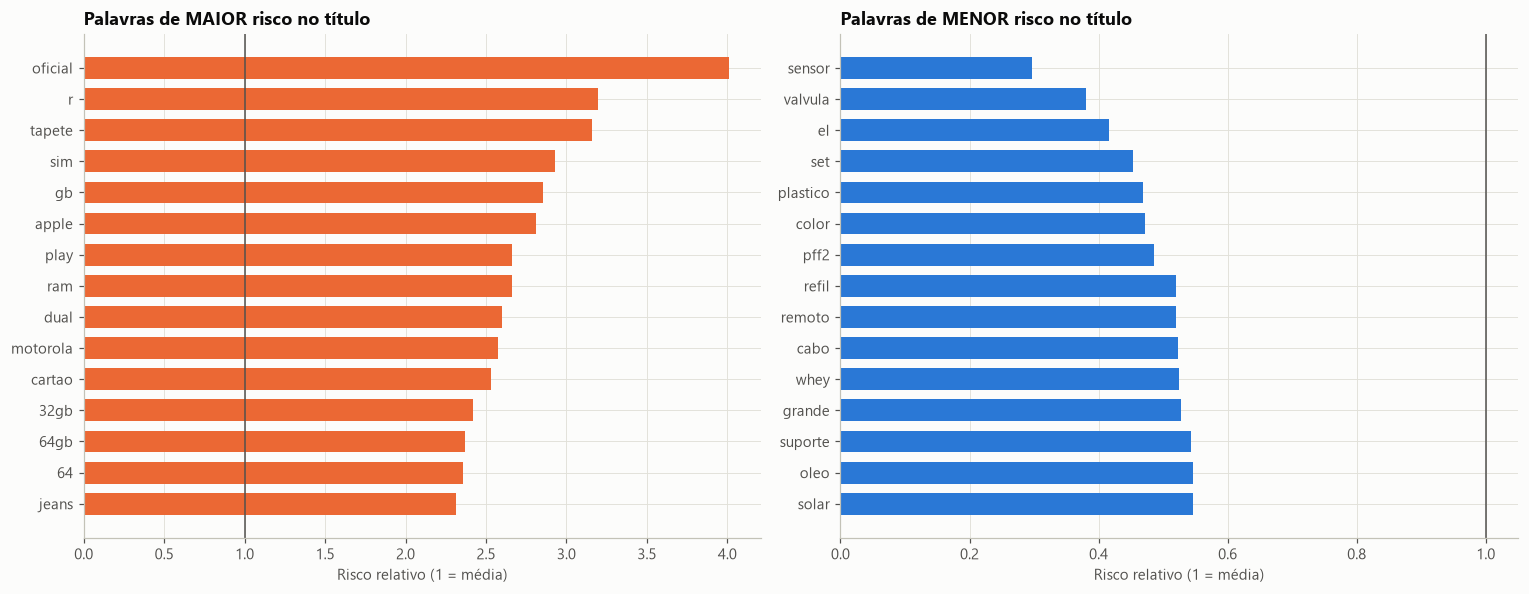

In [10]:
import re, unicodedata

def tokens(s):
    s = unicodedata.normalize("NFKD", str(s).lower())
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    return set(re.sub(r"[^a-z0-9 ]+", " ", s).split())

tk = tr["i"].map(tokens).explode().rename("palavra").to_frame()
tk["fraude"] = y.reindex(tk.index).values
palavras = tk.groupby("palavra")["fraude"].agg(transacoes="size", taxa_fraude="mean")
palavras = palavras[palavras["transacoes"] >= 250]
palavras["risco_relativo"] = palavras["taxa_fraude"] / y.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (titulo, dados_, cor) in zip(axes, [
        ("Palavras de MAIOR risco no título", palavras.nlargest(15, "risco_relativo"), gr.LARANJA),
        ("Palavras de MENOR risco no título", palavras.nsmallest(15, "risco_relativo"), gr.AZUL)]):
    ax.barh(dados_.index[::-1], dados_["risco_relativo"][::-1], color=cor, height=0.7)
    ax.axvline(1, color=gr.TINTA_2, lw=1)
    ax.set(title=titulo, xlabel="Risco relativo (1 = média)")
plt.tight_layout()

O título revela o **modus operandi** do fraudador. 

Os produtos mais visados são **smartphones** (*apple*, *motorola*, *dual sim*, *32gb/64gb*, *ram*), **cartões-presente/recarga** (*cartão*, *play*), produtos "oficiais" de marca e outros itens de **alta liquidez na revenda**, com risco de 2,3x a 4x a média.

Peças e insumos de baixo valor de revenda (sensores, válvulas, refis, cabos, máscaras PFF2) têm metade do risco médio ou menos.

>**Decisão para próximos passos:** criar um **score de risco textual** (TF-IDF + regressão logística sobre o
título), também gerado *out-of-fold*. O modelo final pode receber uma única variável numérica desse
sinal.

## 6. A variável `k`: sinal ou ruído?

Correlação de Spearman entre k e fraude: 0.0023


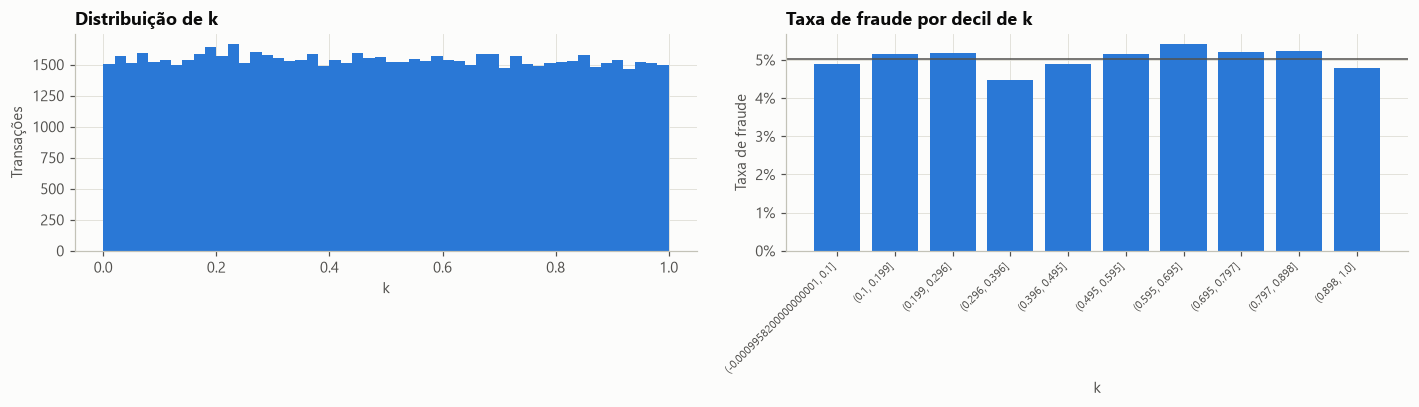

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(tr["k"], bins=50, color=gr.AZUL)
axes[0].set(title="Distribuição de k", xlabel="k", ylabel="Transações")
gr.taxa_fraude_por_faixa(tr, "k", bins=10, ax=axes[1], titulo="Taxa de fraude por decil de k")
plt.tight_layout()
print("Correlação de Spearman entre k e fraude:", round(tr[["k", "fraude"]].corr("spearman").iloc[0, 1], 4))

`k` é **uniforme em [0, 1]**, tem **um valor distinto por transação** e taxa de fraude praticamente **plana** em **todos os decis**. Apresenta todas as características de um número aleatório ou identificador técnico.
Um modelo flexível poderia "decorar" ruído nessa variável. 

> **Decisão para próximos passos:** excluir `k`, que será validado em um teste de ablação futuro.

## 7. Redundância entre variáveis

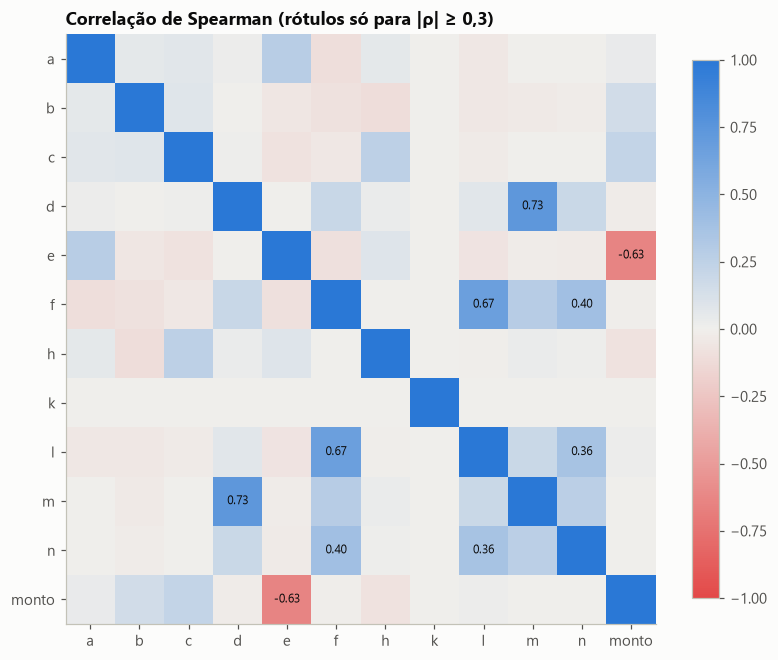

In [12]:
import matplotlib.colors as mcolors
corr = tr[["a", "b", "c", "d", "e", "f", "h", "k", "l", "m", "n", "monto"]].corr(method="spearman")
divergente = mcolors.LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", gr.AZUL])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap=divergente, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns); ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if i != j and abs(corr.iloc[i, j]) >= 0.3:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlação de Spearman (rótulos só para |ρ| ≥ 0,3)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()

Três pares se destacam: **`d`–`m` (0,74)**, **`f`–`l` (0,67)** e **`e`–`monto` (−0,65)**.

Este último sugere que `e` pode ser uma razão com o valor da compra no denominador. 

Nenhum par é redundante a ponto de justificar remoção (ρ < 0,8), e modelos de árvore são robustos a correlação.

>**Decisão para próximos passos:** manter **todas** as variáveis (com exceção de `k`), e a importância final dirá se alguma sobra.

## 8. Estabilidade das distribuições: treino vs validação

Variáveis cuja distribuição muda muito entre períodos são perigosas, porque o modelo aprende um padrão
que deixa de existir. 

Para isso, medimos o **PSI** (*Population Stability Index*). 

>Referências: **< 0,10 estável** - **0,10–0,25 requer atenção** - **> 0,25 instável**.

In [13]:
va = base[base["particao"] == "validacao"]
estab = pd.Series({c: metricas.psi(tr[c], va[c]) for c in numericas}).sort_values(ascending=False)
estab.to_frame("PSI treino→validação").T

,monto,b,h,e,c,d,f,m,k,a,l,n
PSI treino→validação,0.0247,0.0243,0.0107,0.0089,0.0071,0.0040,0.0037,0.0014,0.0005,0.0003,0.0003,0.0000


Todas as variáveis numéricas estão **estáveis** (PSI < 0,10) entre treino e validação, então nenhuma
precisa ser descartada por instabilidade.

## 9. Conclusões *(pergunta 1)*

**Achados**

1. **Variáveis categóricas (`o`, `n`, `p`, `a`):** níveis com risco muito diferente, e o nulo de `o` é o estado mais seguro.
2. **Variáveis de histórico (`f`, `l`, `m`, `d`):** risco concentrado perto de zero, de forma não linear.
3. **Horário:** a fraude se concentra na madrugada.
4. **Categoria (`j`):** taxas de ~1% a ~27% e cauda longa (93% das categorias com < 30 transações).
5. **Título (`i`):** revela produtos de alta liquidez (celulares, gift cards).
6. **País (`g`):** só BR, AR, UY e US têm volume.
7. **`k`:** é ruído.
8. **Estabilidade:** todas as variáveis **numéricas** estáveis entre treino e validação (PSI < 0,1). As
   categóricas e as features derivadas não foram medidas aqui e devem entrar no monitoramento em produção.

**Hipóteses de features (próximos passos)**

- *Mantidas como estão:*
  - Numéricas brutas `a`, `b`, `c`, `d`, `e`, `f`, `h`, `l`, `m`, `n` e `monto`: entram sem transformação,
  com os nulos preservados.

- *Criadas a partir das variáveis originais:*
  - `o_Y`, `o_N`: dummies de `o`, em que o nulo corresponde às duas zeradas, preservando os 3 estados.
  - `p_Y`: versão binária de `p`.
  - `pais_BR`, `pais_AR`, `pais_UY`, `pais_US`, `pais_nulo`: dummies dos países com volume; os demais
    ficam como "outros" (todas zeradas).
  - `hora`, `madrugada` (0h–5h) e `dia_semana`, extraídas de `fecha`.
  - `cat_taxa_fraude`: taxa de fraude da categoria `j`, via **target encoding suavizado out-of-fold**;
    e `cat_volume_log`: volume da categoria.
  - `titulo_score`: risco do título `i`, via **TF-IDF + regressão logística out-of-fold**.

- *Excluídas:*
  - `k` (ruído).
  - `i`, `j`, `fecha`, `o`, `p` e `g` brutas: substituídas pelas versões criadas acima.
  - `score`: o novo modelo deve ser independente do modelo atual, que pretende substituir.

Os padrões são **não lineares e com interações**. Isso aponta para modelos baseados em árvores, o que será testado formalmente em próximos passos.